# ============================================================
# NETGUARD AI
# Notebook 07 - SVM / Scaled Models
# ============================================================

"""
Objective:
Evaluate Support Vector Machine (SVM) for DDoS detection
using standardized network traffic features.

Scientific Question:
Can a scaled, margin-based model such as SVM provide
competitive performance compared with tree-based models?
"""

In [24]:
import pandas as pd
import numpy as np
import time

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [25]:
df = pd.read_csv("netguard_selected_features.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (223082, 21)


,Fwd Packet Length Max,Destination Port,Bwd Packet Length Min,Init_Win_bytes_forward,Subflow Fwd Bytes,act_data_pkt_fwd,Fwd IAT Std,Fwd IAT Mean,Subflow Fwd Packets,Bwd Packet Length Std,...,Bwd IAT Total,Bwd IAT Max,Bwd IAT Mean,Bwd Packets/s,Average Packet Size,min_seg_size_forward,Packet Length Variance,Fwd Packet Length Min,Min Packet Length,Label
0,6,54865,0,33,12,1,0.0,3.0,2,0.0,...,0,0,0.0,0.000000,9.0,20,0.0,6,6,BENIGN
1,6,55054,6,29,6,0,0.0,0.0,1,0.0,...,0,0,0.0,9174.311927,9.0,20,0.0,6,6,BENIGN
2,6,55055,6,29,6,0,0.0,0.0,1,0.0,...,0,0,0.0,19230.769230,9.0,20,0.0,6,6,BENIGN
3,6,46236,6,31,6,0,0.0,0.0,1,0.0,...,0,0,0.0,29411.764710,9.0,20,0.0,6,6,BENIGN
4,6,54863,0,32,12,1,0.0,3.0,2,0.0,...,0,0,0.0,0.000000,9.0,20,0.0,6,6,BENIGN


In [26]:
X = df.drop("Label", axis=1)
y = df["Label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (223082, 20)
Target shape: (223082,)


In [27]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Class mapping:")
for i, class_name in enumerate(label_encoder.classes_):
    print(i, "=", class_name)

Class mapping:
0 = BENIGN
1 = DDoS


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    stratify=y_encoded,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 178465
Testing samples : 44617


In [29]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled :", X_test_scaled.shape)

Training data scaled: (178465, 20)
Testing data scaled : (44617, 20)


In [30]:
SVM_SAMPLE_SIZE = 30000

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X_train_scaled),
    size=SVM_SAMPLE_SIZE,
    replace=False
)

X_train_svm = X_train_scaled[sample_indices]
y_train_svm = y_train[sample_indices]

print("SVM training samples:", X_train_svm.shape[0])
print("Full test samples:", X_test_scaled.shape[0])

SVM training samples: 30000
Full test samples: 44617


In [31]:
SVM_SAMPLE_SIZE = 30000

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X_train_scaled),
    size=SVM_SAMPLE_SIZE,
    replace=False
)

X_train_svm = X_train_scaled[sample_indices]
y_train_svm = y_train[sample_indices]

print("SVM training samples:", X_train_svm.shape[0])
print("Full test samples:", X_test_scaled.shape[0])

SVM training samples: 30000
Full test samples: 44617


In [32]:
start_time = time.time()

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_svm, y_train_svm)

svm_training_time = time.time() - start_time

print(f"SVM training time: {svm_training_time:.2f} seconds")

SVM training time: 18.91 seconds


In [33]:
y_pred_svm = svm_model.predict(X_test_scaled)

y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

In [34]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test,
    y_pred_svm,
    pos_label=1
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    pos_label=1
)

svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    pos_label=1
)

svm_roc_auc = roc_auc_score(
    y_test,
    y_prob_svm
)

print("SVM Results")
print("-" * 40)

print(f"Accuracy : {svm_accuracy:.6f}")
print(f"Precision: {svm_precision:.6f}")
print(f"Recall   : {svm_recall:.6f}")
print(f"F1 Score : {svm_f1:.6f}")
print(f"ROC-AUC  : {svm_roc_auc:.6f}")
print(f"Training Time: {svm_training_time:.2f} seconds")

SVM Results
----------------------------------------
Accuracy : 0.989309
Precision: 0.982376
Recall   : 0.999297
F1 Score : 0.990764
ROC-AUC  : 0.999867
Training Time: 18.91 seconds


In [35]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [36]:

fnr = calculate_fnr(y_test,y_pred_svm )

print(f"SVM FNR: {fnr:.2f}%")

SVM FNR: 0.07%


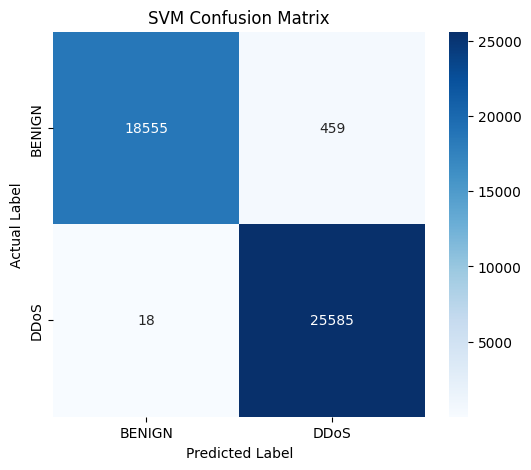

In [37]:
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")

plt.show()

In [38]:
print("SVM Classification Report")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=label_encoder.classes_
    )
)

SVM Classification Report
              precision    recall  f1-score   support

      BENIGN       1.00      0.98      0.99     19014
        DDoS       0.98      1.00      0.99     25603

    accuracy                           0.99     44617
   macro avg       0.99      0.99      0.99     44617
weighted avg       0.99      0.99      0.99     44617



In [39]:
svm_result = pd.DataFrame([{
    "Model": "SVM (RBF)",
    "Accuracy": svm_accuracy,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1": svm_f1,
    "ROC-AUC": svm_roc_auc,
    "Training Time": svm_training_time,
    "FNR (%)": fnr
}])

svm_result

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553,0.070304


In [40]:
baseline_results = pd.read_csv("baseline_model_results.csv")

advanced_results = pd.read_csv("advanced_tree_model_results.csv")

In [41]:
all_results = pd.concat(
    [
        baseline_results,
        advanced_results,
        svm_result
    ],
    ignore_index=True
)

all_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,1.786294,0.093739
1,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,1.499552,0.003906
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,9.005991,0.003906
3,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,92.513001,0.046870
4,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,2.335644,0.003906
5,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,1.193513,0.003906
6,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553,0.070304


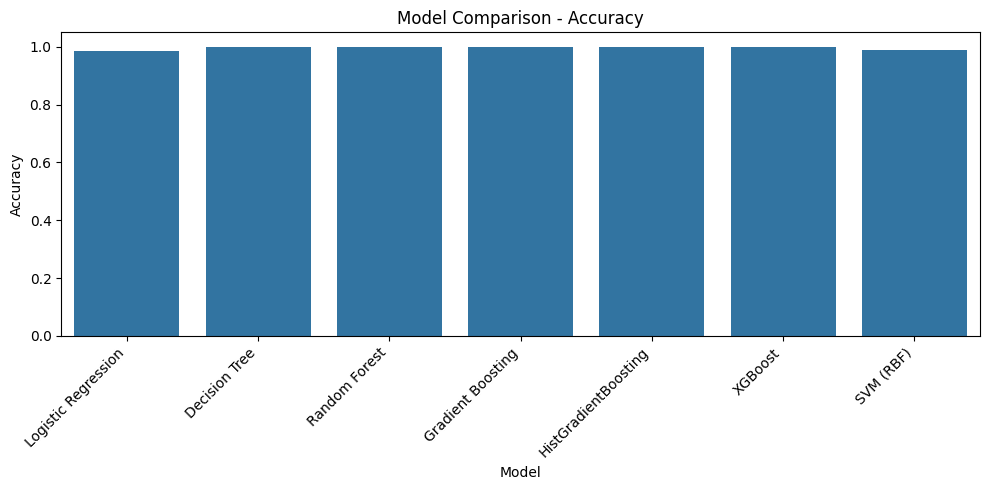

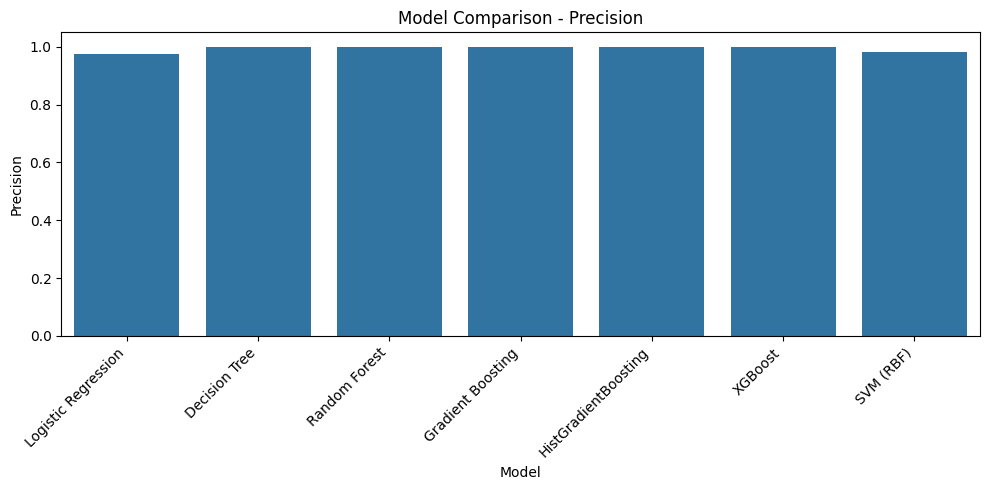

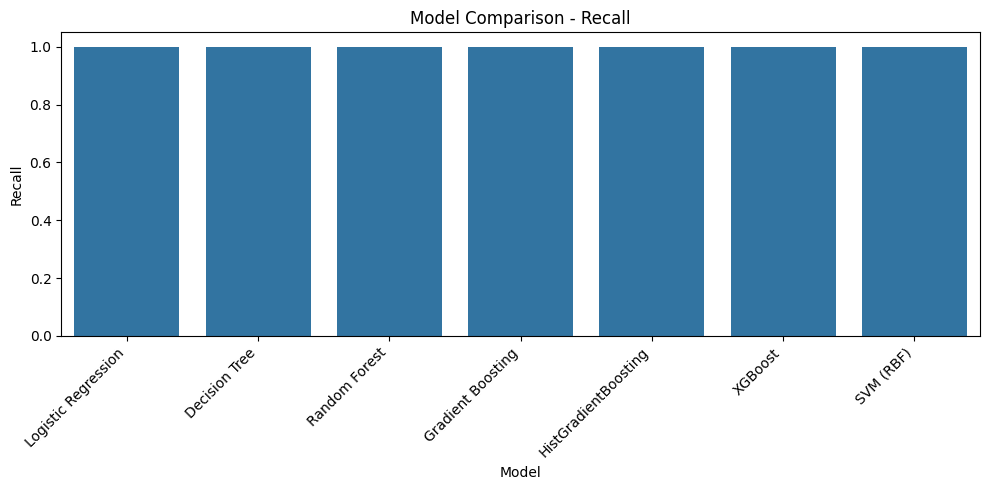

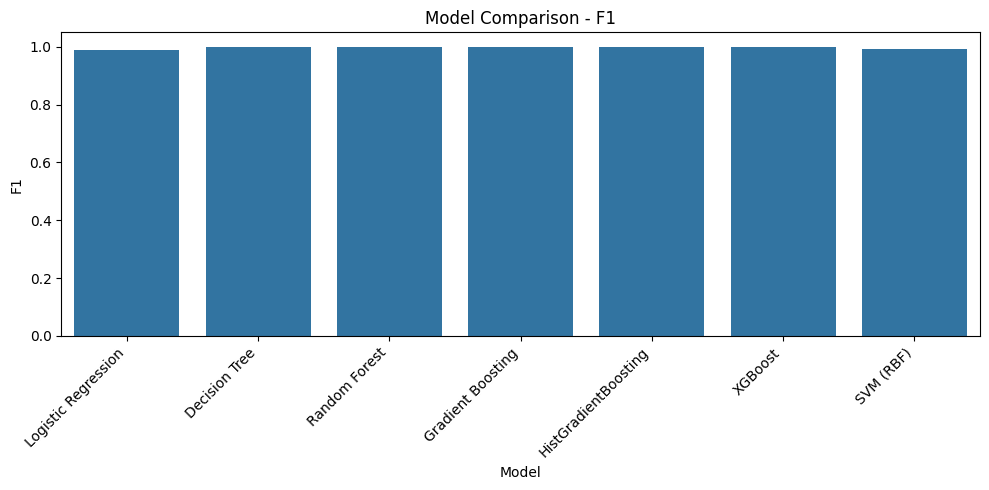

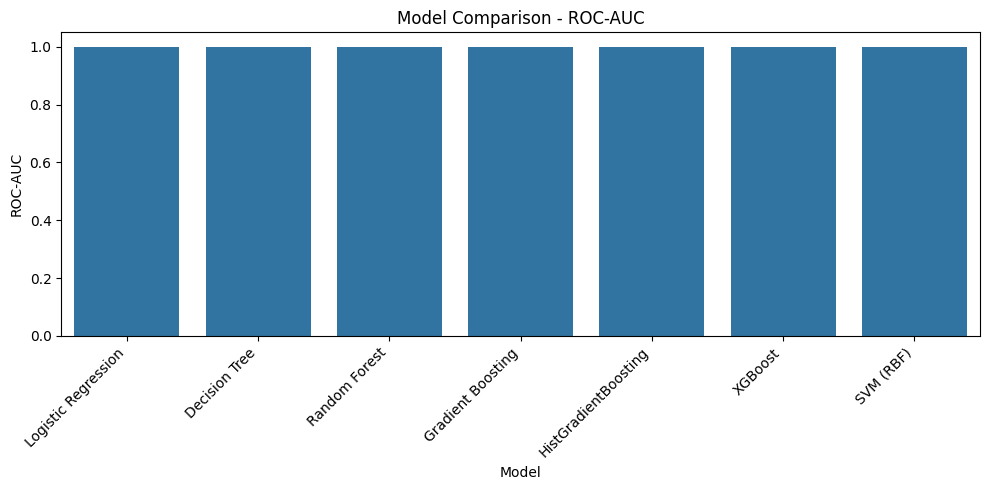

In [42]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=all_results,
        x="Model",
        y=metric
    )

    plt.xticks(rotation=45, ha="right")
    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xlabel("Model")

    plt.tight_layout()
    plt.show()

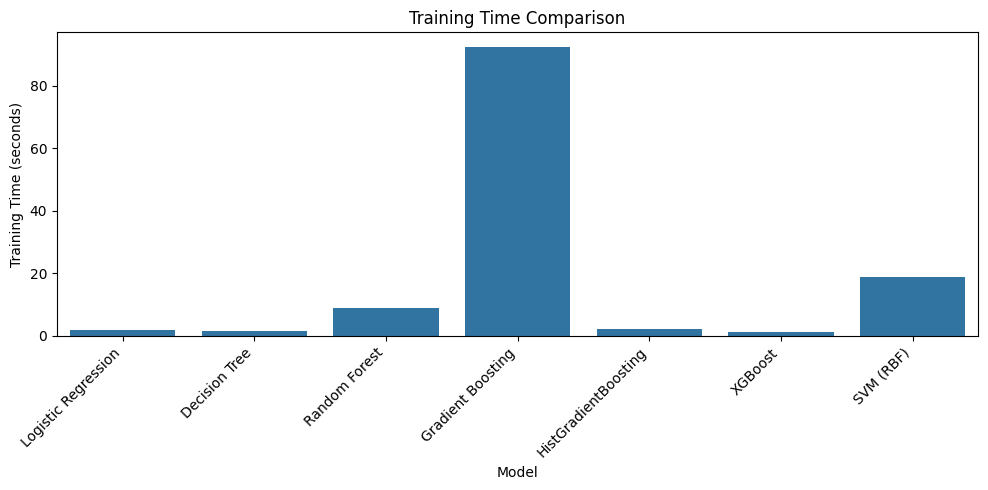

In [43]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=all_results,
    x="Model",
    y="Training Time"
)

plt.xticks(rotation=45, ha="right")
plt.title("Training Time Comparison")
plt.ylabel("Training Time (seconds)")
plt.xlabel("Model")

plt.tight_layout()
plt.show()

In [44]:
y_train_pred_svm = svm_model.predict(X_train_svm)

svm_train_accuracy = accuracy_score(
    y_train_svm,
    y_train_pred_svm
)

svm_test_accuracy = accuracy_score(
    y_test,
    y_pred_svm
)

print("SVM Train Accuracy:", svm_train_accuracy)
print("SVM Test Accuracy :", svm_test_accuracy)

print(
    "Accuracy Gap:",
    svm_train_accuracy - svm_test_accuracy
)

SVM Train Accuracy: 0.9904
SVM Test Accuracy : 0.9893090077773046
Accuracy Gap: 0.001090992222695375


In [45]:
svm_result.to_csv(
    "svm_model_results.csv",
    index=False
)

print("SVM results saved successfully.")

SVM results saved successfully.


In [46]:
all_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,1.786294,0.093739
1,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,1.499552,0.003906
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,9.005991,0.003906
3,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,92.513001,0.046870
4,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,2.335644,0.003906
5,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,1.193513,0.003906
6,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553,0.070304
